In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

# Sesuai Artikel 2 (Leipary & Setiawan): Menggunakan Z-Score (Standardization)
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error,
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from sklearn.preprocessing import RobustScaler

# Mengunci seed agar hasil bisa direproduksi (konsisten)
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

In [ ]:
import pandas as pd
import numpy as np

# Membaca data CSV
df = pd.read_csv("/content/ALL FIX - ALL2.csv")

# Mengubah format kolom menjadi datetime
df["Tanggal"] = pd.to_datetime(df["Tanggal"], dayfirst=False)

# Menentukan kota target
city = "KOTA BANDUNG"

# Memfilter data, mengurutkan berdasarkan waktu, dan mereset index
data = (
    df[df["Kota"] == city]
    .sort_values("Tanggal")
    .reset_index(drop=True)
)

# Mengisolasi fitur utama (Inflasi)
data = data[["Tanggal", "Inflasi"]]

print(f"Dataset {city} siap! Total baris: {len(data)}")
display(data.head())

Dataset KOTA BANDUNG siap! Total baris: 312


,Tanggal,Inflasi
0,2000-01-01,0.60
1,2000-02-01,-0.62
2,2000-03-01,-0.03
3,2000-04-01,-0.04
4,2000-05-01,1.20


In [ ]:
# Menentukan proporsi pembagian (80% Train, 20% Test)
train_size = int(len(data) * 0.8)

# Membagi dataframe mentah secara sekuensial
data_train = data.iloc[:train_size].copy().reset_index(drop=True)
data_test = data.iloc[train_size:].copy().reset_index(drop=True)

print("=" * 50)
print("PEMBAGIAN DATA MENTAH (80:20)")
print("=" * 50)
print(f"Total Baris Data : {len(data)}")
print(f"Jumlah Data Latih (Train) : {len(data_train)} ({len(data_train)/len(data)*100:.1f}%)")
print(f"Jumlah Data Uji (Test)    : {len(data_test)} ({len(data_test)/len(data)*100:.1f}%)")

PEMBAGIAN DATA MENTAH (80:20)
Total Baris Data : 312
Jumlah Data Latih (Train) : 249 (79.8%)
Jumlah Data Uji (Test)    : 63 (20.2%)


In [ ]:
from sklearn.preprocessing import StandardScaler

# Inisialisasi scaler
scaler_inflasi = StandardScaler()

# 1. Fit & Transform HANYA pada data train
data_train["Inflasi_scaled"] = scaler_inflasi.fit_transform(data_train[["Inflasi"]])

# 2. Transform data test menggunakan statistik dari data train
data_test["Inflasi_scaled"] = scaler_inflasi.transform(data_test[["Inflasi"]])

print("Standarisasi Berhasil!")
print("Data Train Ter-skala:")
display(data_train.head(3))

Standarisasi Berhasil!
Data Train Ter-skala:


,Tanggal,Inflasi,Inflasi_scaled
0,2000-01-01,0.60,0.105781
1,2000-02-01,-0.62,-1.430274
2,2000-03-01,-0.03,-0.687427


In [ ]:
lag = 12

# Fungsi helper untuk membuat sequence windowing
def create_sequences(data_array, lag):
    X, y = [], []
    for i in range(lag, len(data_array)):
        X.append(data_array[i - lag : i])
        y.append(data_array[i])
    return np.array(X), np.array(y)

# 1. Windowing untuk Data Train
train_values = data_train["Inflasi_scaled"].values
X_train, y_train = create_sequences(train_values, lag)

# 2. Windowing untuk Data Test
# Agar 12 baris pertama pada data Test tetap memiliki histori dari akhir data Train:
test_history = np.concatenate([train_values[-lag:], data_test["Inflasi_scaled"].values])
X_test, y_test = create_sequences(test_history, lag)

# Reshape ke format 3D LSTM: (Samples, Timesteps/Lag, Features)
X_train = np.expand_dims(X_train, axis=-1)
X_test = np.expand_dims(X_test, axis=-1)

print("=" * 50)
print("HASIL PEMBUATAN SEQUENCE (3D INPUT LSTM)")
print("=" * 50)
print(f"Bentuk X_train : {X_train.shape}  --> (Batch, Lag, Fitur)")
print(f"Bentuk y_train : {y_train.shape}")
print(f"Bentuk X_test  : {X_test.shape}")
print(f"Bentuk y_test  : {y_test.shape}")

HASIL PEMBUATAN SEQUENCE (3D INPUT LSTM)
Bentuk X_train : (237, 12, 1)  --> (Batch, Lag, Fitur)
Bentuk y_train : (237,)
Bentuk X_test  : (63, 12, 1)
Bentuk y_test  : (63,)


In [ ]:
print("=" * 50)
print("VERIFIKASI BENTUK DATA (INPUT LAYER 3D LSTM)")
print("=" * 50)

print(f"X_train Shape : {X_train.shape}  --> (Sampel Train, Time Steps, Fitur)")
print(f"X_test Shape  : {X_test.shape}   --> (Sampel Test, Time Steps, Fitur)")
print("-" * 50)
print(f"y_train Shape : {y_train.shape}")
print(f"y_test Shape  : {y_test.shape}")

VERIFIKASI BENTUK DATA (INPUT LAYER 3D LSTM)
X_train Shape : (237, 12, 1)  --> (Sampel Train, Time Steps, Fitur)
X_test Shape  : (63, 12, 1)   --> (Sampel Test, Time Steps, Fitur)
--------------------------------------------------
y_train Shape : (237,)
y_test Shape  : (63,)


In [ ]:
# Membangun arsitektur model Stacked LSTM (256 -> 128 -> 64 -> 1)
model = Sequential([
    # Input Layer (Timesteps=12, Fitur=2)
    Input(shape=(X_train.shape[1], X_train.shape[2])),

    # LSTM Layer 1 (256 units)
    LSTM(units=256, return_sequences=True),
    Dropout(0.1),

    # LSTM Layer 2 (128 units)
    LSTM(units=128, return_sequences=True),
    Dropout(0.1),

    # LSTM Layer 3 (64 units)
    LSTM(units=64, return_sequences=False),
    Dropout(0.1),

    # Output Layer (1 unit target: Inflasi)
    Dense(units=1)
])

# Kompilasi model dengan Optimizer Adam
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mean_squared_error",
    metrics=["mae"]
)

# Menampilkan ringkasan arsitektur model
print("=" * 50)
print("RINGKASAN ARSITEKTUR MODEL STACKED LSTM")
print("=" * 50)
model.summary()

RINGKASAN ARSITEKTUR MODEL STACKED LSTM


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_9 (LSTM)                   │ (None, 12, 256)        │       264,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 12, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_10 (LSTM)                  │ (None, 12, 128)        │       197,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 12, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_11 (LSTM)                  │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 510,785 (1.95 MB)

 Trainable params: 510,785 (1.95 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Melakukan training model
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=128,
    shuffle=False,
    validation_data=(X_test, y_test),  # <-- TAMBAHKAN BARIS INI
    verbose=1
)

# Menampilkan informasi ringkas setelah pelatihan selesai
print("\n" + "=" * 50)
print("PELATIHAN MODEL SELESAI!")
print("=" * 50)
print(f"Loss Akhir (Train MSE) : {history.history['loss'][-1]:.6f}")
print(f"Loss Akhir (Val MSE)   : {history.history['val_loss'][-1]:.6f}")

Epoch 1/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 10s 788ms/step - loss: 1.0024 - mae: 0.6043 - val_loss: 0.4470 - val_mae: 0.4781
Epoch 2/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 240ms/step - loss: 0.9835 - mae: 0.5977 - val_loss: 0.4255 - val_mae: 0.4507
Epoch 3/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 249ms/step - loss: 0.9847 - mae: 0.5987 - val_loss: 0.4221 - val_mae: 0.4467
Epoch 4/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 262ms/step - loss: 0.9775 - mae: 0.5906 - val_loss: 0.4215 - val_mae: 0.4467
Epoch 5/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 250ms/step - loss: 0.9754 - mae: 0.5884 - val_loss: 0.4198 - val_mae: 0.4395
Epoch 6/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 257ms/step - loss: 0.9713 - mae: 0.5859 - val_loss: 0.4280 - val_mae: 0.4356
Epoch 7/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 225ms/step - loss: 0.9698 - mae: 0.5858 - val_loss: 0.4393 - val_mae: 0.4449
Epoch 8/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 260ms/step - loss: 0.9674 - mae: 0.5874 - val_loss: 0.4371 - val_mae: 0.4485
Epoch 9/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 239ms/step - loss: 0.96

In [ ]:
# 1. Melakukan prediksi pada data testing
y_pred = model.predict(X_test)

# 2. Mengembalikan hasil prediksi ke skala asli (% inflasi)
y_pred_inverse = scaler_inflasi.inverse_transform(y_pred)

# 3. Mengembalikan data aktual ke skala asli (% inflasi)
y_test_inverse = scaler_inflasi.inverse_transform(y_test.reshape(-1, 1))

# Menampilkan perbandingan 5 data pertama
print("\n" + "=" * 50)
print("HASIL INVERSE TRANSFORM (SKALA ASLI)")
print("=" * 50)

print("5 Data Aktual Pertama (% Inflasi):")
print(y_test_inverse[:5].flatten())

print("\n5 Data Prediksi Pertama (% Inflasi):")
print(y_pred_inverse[:5].flatten())

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 568ms/step

HASIL INVERSE TRANSFORM (SKALA ASLI)
5 Data Aktual Pertama (% Inflasi):
[0.08 0.26 0.39 0.1  0.09]

5 Data Prediksi Pertama (% Inflasi):
[0.16729113 0.18361405 0.28357822 0.25848582 0.2506205 ]


In [ ]:
# 1. Menghitung Mean Squared Error (MSE)
mse = mean_squared_error(y_test_inverse, y_pred_inverse)

# 2. Menghitung Root Mean Squared Error (RMSE)
rmse = np.sqrt(mse)

# 3. Menghitung Mean Absolute Error (MAE)
mae = mean_absolute_error(y_test_inverse, y_pred_inverse)

# 4. Menghitung Symmetric Mean Absolute Percentage Error (sMAPE)
# Menghindari pembagian dengan nol menggunakan np.where
denom = np.abs(y_test_inverse) + np.abs(y_pred_inverse)
smape_ratio = np.mean(np.where(denom == 0, 0, 2 * np.abs(y_pred_inverse - y_test_inverse) / denom))
smape_pct = smape_ratio * 100

# Menampilkan hasil evaluasi model
print("=" * 50)
print("HASIL EVALUASI MODEL")
print("=" * 50)
print(f"MSE   : {mse:.6f}")
print(f"RMSE  : {rmse:.6f}")
print(f"MAE   : {mae:.6f}")

HASIL EVALUASI MODEL
MSE   : 0.305832
RMSE  : 0.553021
MAE   : 0.355576


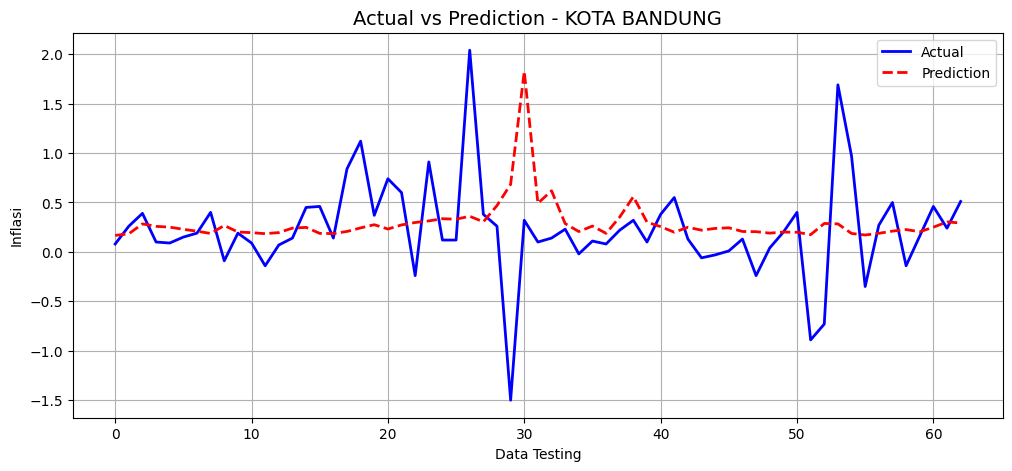

In [ ]:
plt.figure(figsize=(12,5))

plt.plot(
    y_test_inverse,
    color='blue',
    linewidth=2,
    label='Actual'
)

plt.plot(
    y_pred_inverse,
    color='red',
    linestyle='--',
    linewidth=2,
    label='Prediction'
)

plt.title(
    f'Actual vs Prediction - {city}',
    fontsize=14
)

plt.xlabel("Data Testing")

plt.ylabel("Inflasi")

plt.legend()

plt.grid(True)

plt.show()

### SELESAI